# Predicting Sales Prices

 ## Dataset Attributes

 The dataset contains information about houses in Ames, Iowa. The data was collected by the Ames City Assessor’s Office describing 2930 property sales which occurred in Ames, Iowa between 2006 and 2010. The dataset, containing 81 variables, was compiled and published by De Cock in 2011.

 Some of the variables contained in the original dataset have been removed from the the dataset provided to you.
 The dataset provided to you contains the following variables:
* **Year_Built:** year that the house was originally constructed
* **Year_Remod_Add:** year that the house was last remodelled
* **Total_Bsmt_SF:** total size of basement area in square feet
* **First_Flr_SF:** size of the first floor in square feet
* **Second_Flr_SF:** size of the second floor in square feet
* **Gr_Liv_Area:** size of above grade, ground living area in square feet
* **Full_Bath:** number of full above grade bathrooms in the house
* **Half_Bath:** number of half above grade bathrooms in the house
* **Bedroom_AbvGr:** number of above grade bedrooms (does not include basement bedrooms)
* **Kitchen_AbvGr:** number of above grade kitchens
* **TotRms_AbvGrd:** total number of above grade rooms (does not include bathrooms)
* **Fireplaces:** number of fireplaces in the house
* **Garage_Area:** size of garage in square feet
* **Sale_Price:** sale price of the house in dollars


*De Cock, D. (2011). "Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester
Regression Project," Journal of Statistics Education, Volume 19, Number 3.*

- https://ww2.amstat.org/publications/jse/v19n3/decock/DataDocumentation.txt
- http://ww2.amstat.org/publications/jse/v19n3/decock.pdf


 ## Objective

 The goal of this task is to analyse the relationship between these variables and build a multiple linear regression model to predict the sales prices based on the 'Gr_Liv_Area' and 'Garage_Area` variables.


In [47]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [48]:
# Read in the data set

df = pd.read_csv ('ames.csv')
df.head()

,Year_Built,Year_Remod_Add,Total_Bsmt_SF,First_Flr_SF,Second_Flr_SF,Gr_Liv_Area,Full_Bath,Half_Bath,Bedroom_AbvGr,Kitchen_AbvGr,TotRms_AbvGrd,Fireplaces,Garage_Area,Sale_Price
0,1960,1960,1080,1656,0,1656,1,0,3,1,7,2,528,215000
1,1961,1961,882,896,0,896,1,0,2,1,5,0,730,105000
2,1958,1958,1329,1329,0,1329,1,1,3,1,6,0,312,172000
3,1968,1968,2110,2110,0,2110,2,1,3,1,8,2,522,244000
4,1997,1998,928,928,701,1629,2,1,3,1,6,1,482,189900


In [49]:
# Clean and pre-process the data if necessary
print(df.isnull().sum())
print(df.info())
 # No missing values in this dataset, so no imputation or dropping needed

Year_Built        0
Year_Remod_Add    0
Total_Bsmt_SF     0
First_Flr_SF      0
Second_Flr_SF     0
Gr_Liv_Area       0
Full_Bath         0
Half_Bath         0
Bedroom_AbvGr     0
Kitchen_AbvGr     0
TotRms_AbvGrd     0
Fireplaces        0
Garage_Area       0
Sale_Price        0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Year_Built      2930 non-null   int64
 1   Year_Remod_Add  2930 non-null   int64
 2   Total_Bsmt_SF   2930 non-null   int64
 3   First_Flr_SF    2930 non-null   int64
 4   Second_Flr_SF   2930 non-null   int64
 5   Gr_Liv_Area     2930 non-null   int64
 6   Full_Bath       2930 non-null   int64
 7   Half_Bath       2930 non-null   int64
 8   Bedroom_AbvGr   2930 non-null   int64
 9   Kitchen_AbvGr   2930 non-null   int64
 10  TotRms_AbvGrd   2930 non-null   int64
 11  Fireplaces      2930 non-null   int6

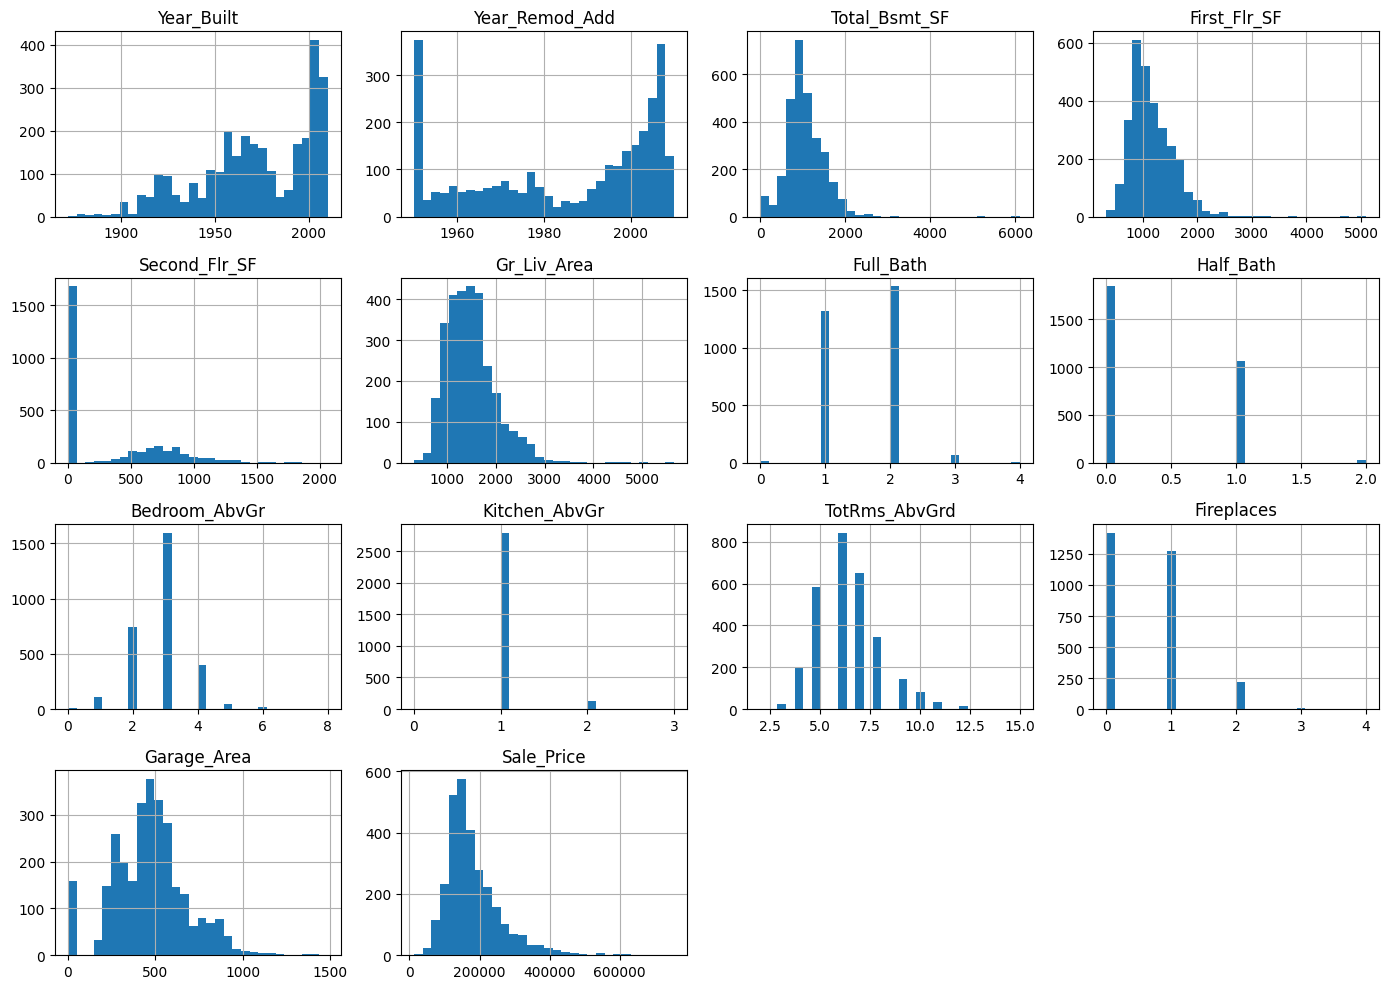

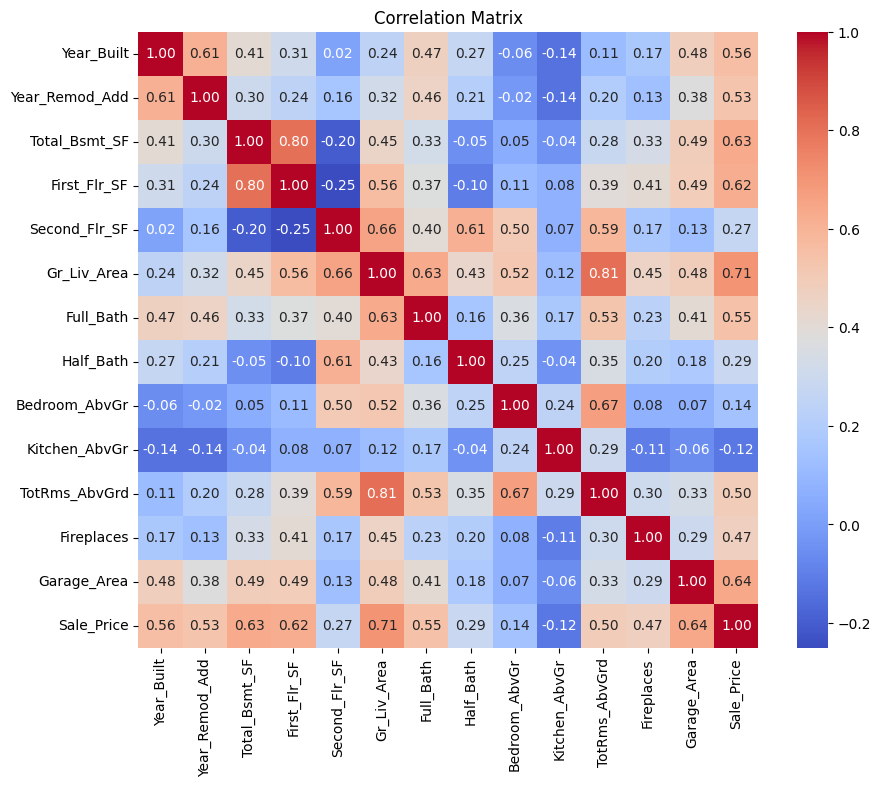

In [50]:
# Explore the data with visualisations such as histograms and correlation matrices
df.hist(figsize=(14, 10), bins=30)
plt.tight_layout()
plt.show()
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [51]:
# Split the independent variables from the dependent variable
X = df[['Gr_Liv_Area', 'Garage_Area']]
y = df['Sale_Price']

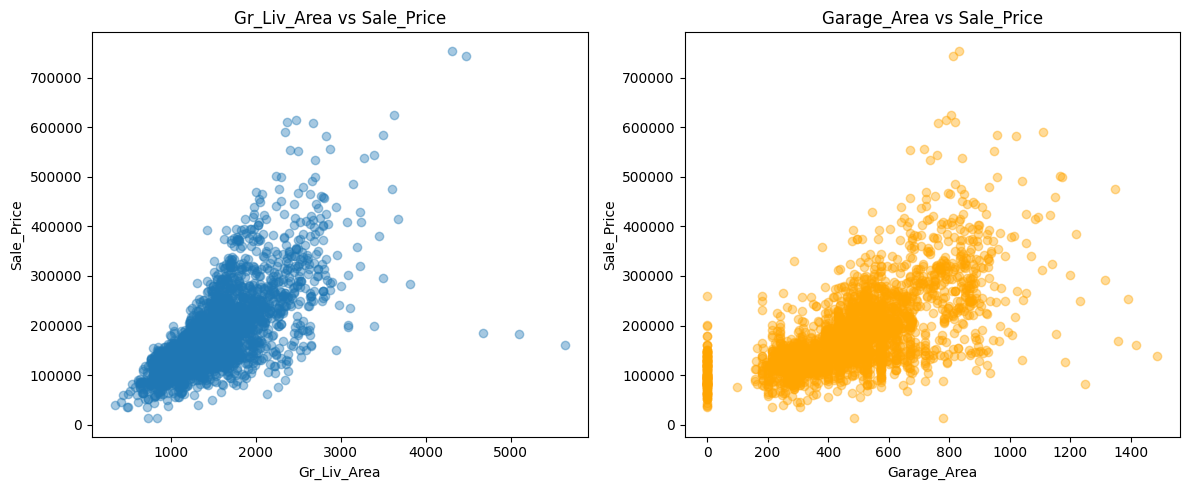

In [52]:
# Generate plots to explore the relationships between the independent and dependent variables
fig, axes = plt.subplots(1,2, figsize=(12, 5))
axes[0].scatter(df['Gr_Liv_Area'], df['Sale_Price'], alpha=0.4)
axes[0].set_xlabel('Gr_Liv_Area')
axes[0].set_ylabel('Sale_Price')
axes[0].set_title('Gr_Liv_Area vs Sale_Price')
axes[1].scatter(df['Garage_Area'], df['Sale_Price'], alpha=0.4, color='orange')
axes[1].set_xlabel('Garage_Area')
axes[1].set_ylabel('Sale_Price')
axes[1].set_title('Garage_Area vs Sale_Price')

plt.tight_layout()
plt.show()

In [53]:
# Create a training and test set with a 75:25 split ratio

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [54]:
# Build a multiple linear regression model using 'Gr_Liv_Area' and 'Garage_Area'
model = LinearRegression()
model.fit(X_train, y_train);

In [55]:
# Print the trained model's intercept and coefficients
print("Intercept:", model.intercept_)
print("Coefficients:", dict(zip(X.columns, model.coef_)))

Intercept: -5059.448195610574
Coefficients: {'Gr_Liv_Area': np.float64(78.69286848121413), 'Garage_Area': np.float64(141.14571760877217)}


In [56]:
# Generate predictions for the test set
y_pred = model.predict(X_test)

In [57]:
# Evaluate the model's performance by computing the mean squared error (MSE) or root mean squared error (RMSE) on the test set using sklearn.metrics.
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")

Mean Squared Error (MSE): 2634371879.69
Root Mean Squared Error (RMSE): 51326.13


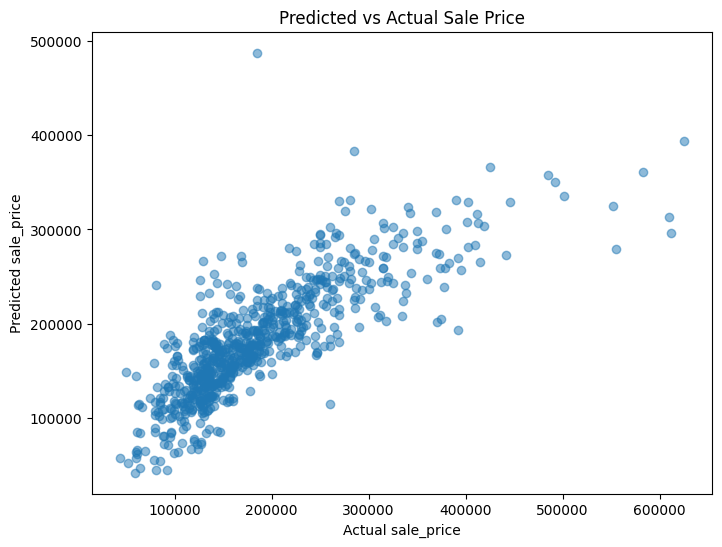

In [58]:
# Generate an error plot to visualise the differences between the predicted and actual values in the test set.
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Actual sale_price")
plt.ylabel("Predicted sale_price")
plt.title("Predicted vs Actual Sale Price")
plt.show()

In [59]:
# Print the coefficients and interpret them within the context of the median value prediction.
median_price = df['Sale_Price'].median()
print(f"Median Sale Price: {median_price:.2f}")
print(f"Intercept: {model.intercept_:.2f}")
print(f"Gr_Liv_Area Coefficient: {model.coef_[0]:.2f}")
print(f"Garage_Area Coefficient: {model.coef_[1]:.2f}")

Median Sale Price: 160000.00
Intercept: -5059.45
Gr_Liv_Area Coefficient: 78.69
Garage_Area Coefficient: 141.15


**Interpret coefficients in the context of the prediction:**
[Answer here]

The intercept is - $5,059.45, which isn't meaningful on its own since no house has zero size.The Gr_Liv_Area coefficient is 78.69, so each extra square foot of living space adds about $78.69 to the predicted price.The Garage_Area coefficient is 141.15,so each extra square foot of garage adds about $141.15.Garage space actually has a bigger per-square-foot effect than living space here,likely because garages are much smaller overall,so each additional foot counts for more. Against the median sale price of $160,000, a 100 sq ft increase in living area would add roughly $7,869, and the same increase in garage area would add about $14,115.

**Summarise findings**
[Answer here]

Sale_Price,Gr_Liv_Area, and Garage_Area were all right-skewed ,with a few large,expensive houses stretching the distributions.Both variables correlated well with Sale_Price(0.71 and 0.64),supporting their use in the model.The scatter plots showed clear positive trends, though the spread widened at higher values.The model(intercept - $5,059.45, coefficients 78.69 and 141.15)predicted well for typical, lower-priced homes,suggesting other features like basement size or year built could improve the fit.